# Ciclo de vida del modelo: chatbot de preguntas frecuentes UPQ

**Objetivo:** comparar cuatro clasificadores supervisados sobre el mismo corpus, con el
mismo procedimiento de evaluación (validación cruzada estratificada, F1 macro y matrices
de confusión), y justificar cuál se usa en el chatbot.

**Restricción de la tarea:** solo aprendizaje supervisado clásico con TF-IDF y
scikit-learn, todo local.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

RAIZ = Path.cwd().parent
assert (RAIZ / "src").exists(), f"No encuentro src/ en {RAIZ}; ¿abriste el notebook desde notebooks/?"
sys.path.insert(0, str(RAIZ))

from src.preprocesamiento import limpiar_texto

print("Proyecto:", RAIZ)

Proyecto: /home/baz/Downloads/repos/chatbot-upq


390 ejemplos, 18 intenciones
intencion
ingles_idiomas            25
servicios_escolares       25
ubicacion_transporte      25
contacto_horarios         25
biblioteca_actividades    25
admision                  24
calendario_escolar        21
becas                     20
saludo                    20
despedida                 20
agradecimiento            20
oferta_educativa          20
costos_pagos              20
reinscripcion             20
estadias                  20
servicio_social           20
titulacion                20
movilidad_intercambio     20
Name: count, dtype: int64


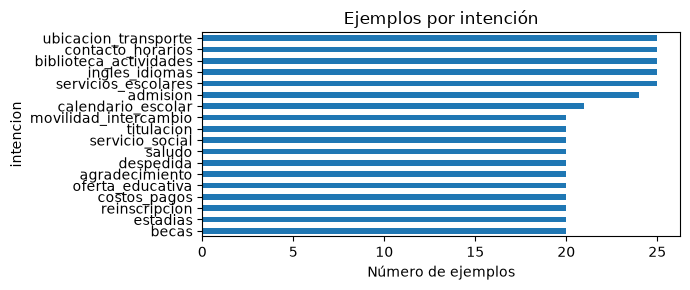

In [2]:
corpus = pd.read_csv(RAIZ / "data" / "corpus_upq.csv")
conteo = corpus["intencion"].value_counts()
print(f"{len(corpus)} ejemplos, {corpus['intencion'].nunique()} intenciones")
print(conteo)

conteo.sort_values().plot.barh(figsize=(7, 3), title="Ejemplos por intención")
plt.xlabel("Número de ejemplos")
plt.tight_layout()
plt.show()

In [3]:
corpus["texto_limpio"] = corpus["texto"].map(limpiar_texto)
corpus[["texto", "texto_limpio"]].sample(5, random_state=42)

,texto,texto_limpio
9,requisitos para una beca de excelencia,requisitos para una beca de excelencia
42,hola buen día,hola buen dia
33,buenas,buenas
311,cuanto tarda en salir mi kardex,cuanto tarda en salir mi kardex
272,como me voy de intercambio,como me voy de intercambio


In [4]:
X = corpus["texto_limpio"]
y = corpus["intencion"]

n_splits = min(5, y.value_counts().min())
folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
print(f"Validación cruzada estratificada con {n_splits} folds")


def tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)


modelos = {
    "LogisticRegression (C=1)": LogisticRegression(max_iter=1000, random_state=42),
    "LogisticRegression (C=10)": LogisticRegression(C=10, max_iter=1000, random_state=42),
    "LinearSVC": LinearSVC(random_state=42),
    "MultinomialNB": MultinomialNB(),
    "KNN (coseno, k=3)": KNeighborsClassifier(n_neighbors=3, metric="cosine"),
}
pipelines = {n: Pipeline([("tfidf", tfidf()), ("clf", clf)]) for n, clf in modelos.items()}

filas = []
for nombre, pipe in pipelines.items():
    r = cross_validate(pipe, X, y, cv=folds, scoring=["f1_macro", "accuracy"])
    filas.append({
        "modelo": nombre,
        "f1_macro": r["test_f1_macro"].mean(),
        "f1_desv": r["test_f1_macro"].std(),
        "accuracy": r["test_accuracy"].mean(),
        "acc_desv": r["test_accuracy"].std(),
    })

resultados = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
resultados.round(3)

Validación cruzada estratificada con 5 folds


,modelo,f1_macro,f1_desv,accuracy,acc_desv
0,LogisticRegression (C=10),0.801,0.043,0.803,0.039
1,LinearSVC,0.791,0.048,0.795,0.042
2,LogisticRegression (C=1),0.759,0.049,0.769,0.044
3,MultinomialNB,0.721,0.032,0.738,0.031
4,"KNN (coseno, k=3)",0.607,0.015,0.613,0.021


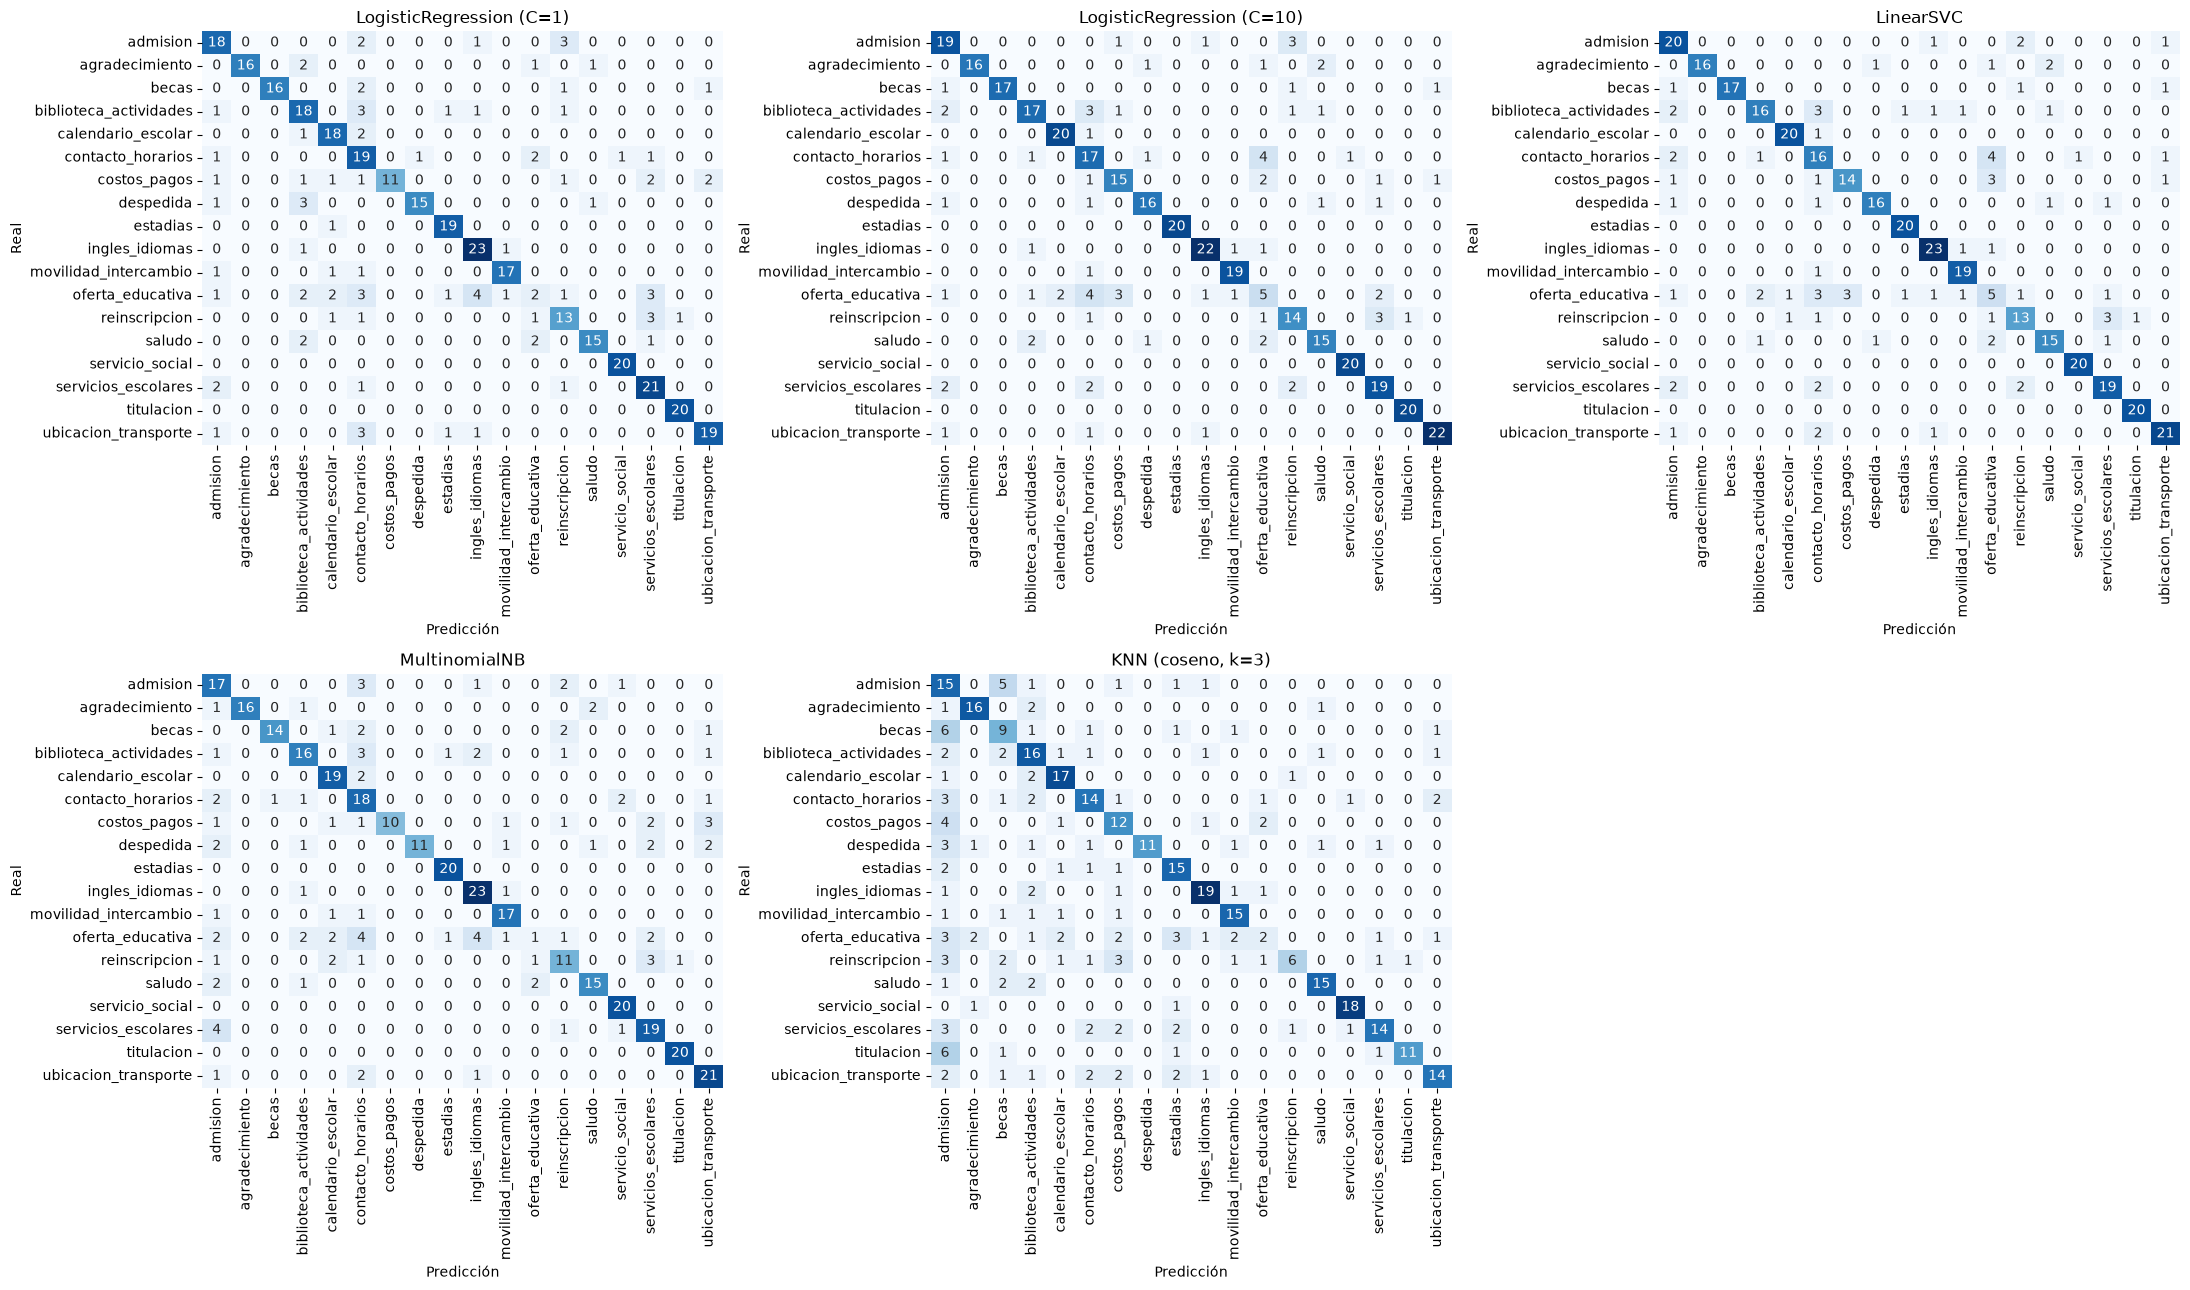

In [5]:
orden = sorted(y.unique())
predicciones = {}

fig, ejes = plt.subplots(2, 3, figsize=(22, 13))
for eje, (nombre, pipe) in zip(ejes.ravel(), pipelines.items()):
    pred = cross_val_predict(pipe, X, y, cv=folds)
    predicciones[nombre] = pred
    cm = confusion_matrix(y, pred, labels=orden)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=orden, yticklabels=orden, ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Real")
for eje in ejes.ravel()[len(pipelines):]:
    eje.axis("off")

plt.tight_layout()
plt.show()

In [6]:
mejor = resultados.loc[0, "modelo"]
print(f"Reporte del mejor modelo según F1 macro: {mejor}\n")
print(classification_report(y, predicciones[mejor], zero_division=0))

Reporte del mejor modelo según F1 macro: LogisticRegression (C=10)

                        precision    recall  f1-score   support

              admision       0.68      0.79      0.73        24
        agradecimiento       1.00      0.80      0.89        20
                 becas       1.00      0.85      0.92        20
biblioteca_actividades       0.77      0.68      0.72        25
    calendario_escolar       0.91      0.95      0.93        21
     contacto_horarios       0.53      0.68      0.60        25
          costos_pagos       0.75      0.75      0.75        20
             despedida       0.84      0.80      0.82        20
              estadias       1.00      1.00      1.00        20
        ingles_idiomas       0.88      0.88      0.88        25
 movilidad_intercambio       0.90      0.95      0.93        20
      oferta_educativa       0.31      0.25      0.28        20
         reinscripcion       0.67      0.70      0.68        20
                saludo       0.79  

In [7]:
errores = corpus.assign(prediccion=predicciones[mejor])
errores = errores[errores["intencion"] != errores["prediccion"]]
print(f"{len(errores)} errores de {len(corpus)} ejemplos con {mejor}")
display(errores[["texto", "intencion", "prediccion"]])

print("Confusiones más frecuentes (real -> predicción):")
errores[["intencion", "prediccion"]].value_counts().head(8)

77 errores de 390 ejemplos con LogisticRegression (C=10)


,texto,intencion,prediccion
0,¿Cómo me inscribo a la UPQ?,admision,reinscripcion
2,quiero ser alumno nuevo que tengo que hacer,admision,reinscripcion
10,quiero una veca para estudiar,becas,admision
23,beca de transporte,becas,ubicacion_transporte
28,beka academica,becas,reinscripcion
...,...,...,...
378,desarrollo humano upq,biblioteca_actividades,contacto_horarios
380,hay rondalla,biblioteca_actividades,saludo
381,clubes de la universidad,biblioteca_actividades,contacto_horarios
387,puedo pedir libros prestados,biblioteca_actividades,costos_pagos


Confusiones más frecuentes (real -> predicción):


intencion               prediccion            
oferta_educativa        contacto_horarios         4
contacto_horarios       oferta_educativa          4
admision                reinscripcion             3
oferta_educativa        costos_pagos              3
reinscripcion           servicios_escolares       3
biblioteca_actividades  contacto_horarios         3
saludo                  oferta_educativa          2
                        biblioteca_actividades    2
Name: count, dtype: int64

## Conclusión (corpus completo: 390 ejemplos, 18 intenciones)

**Procedimiento.** Los cinco modelos se evaluaron con el mismo `Pipeline` (TF-IDF de
caracteres `char_wb` 3-5 con `sublinear_tf`) y los mismos 5 folds (`StratifiedKFold`,
`random_state=42`). El TF-IDF se ajusta solo con el entrenamiento de cada fold, para
evitar fuga de datos.

**Resultados (F1 macro ± desviación).** LogisticRegression C=10: 0.801 ± 0.043;
LinearSVC: 0.791 ± 0.048; LogisticRegression C=1: 0.759 ± 0.049; MultinomialNB:
0.721 ± 0.032; KNN: 0.607 ± 0.015.

**Elección: Regresión Logística con C=10.** Obtiene el mejor F1 macro, aunque LinearSVC
queda a menos de una desviación estándar, así que el F1 por sí solo no los separa. Se
elige Regresión Logística porque da probabilidades nativas (`predict_proba`), que necesita
el fallback por umbral, sin calibración adicional. C=10 supera a C=1 por 0.042, casi una
desviación estándar.

**Umbrales** (`scripts/calibrar_umbrales.py`, con `data/fuera_de_alcance.csv`):
`umbral_alto` = 0.58 y `umbral_bajo` = 0.26. El 41 % de las preguntas válidas recibe
respuesta directa con 97 % de acierto, el 40 % pasa por "¿Quisiste decir…?" y el 19 %
cae en fallback; se rechaza el 77 % de las preguntas ajenas que pasan los guardrails.

**Errores.** El modelo falla 77 de 390 ejemplos. Las confusiones se concentran en
intenciones que comparten vocabulario: `oferta_educativa` y `contacto_horarios`,
`admision` y `reinscripcion`, `oferta_educativa` y `costos_pagos`, y `reinscripcion`
y `servicios_escolares`.